In [4]:
from pathlib import Path

PROJECT_ROOT = Path.home() / "UltraCNN"
DATASET_ROOT = PROJECT_ROOT / "data" / "kitti" / "stereo2012"

SPLIT = "training"
IMAGE_ID = "000000"

left_path = (
    DATASET_ROOT
    / "data_stereo_flow"
    / SPLIT
    / "colored_0"
    / f"{IMAGE_ID}_10.png"
)

assert left_path.is_file(), f"Image not found: {left_path}"

In [1]:
import cv2
import torch
import matplotlib.pyplot as plt

from ultralytics import YOLO

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
CUDA available: True
GPU: NVIDIA GeForce GTX 1650


In [2]:
model = YOLO("yolo11n.pt")

print("YOLO model loaded successfully.")

YOLO model loaded successfully.


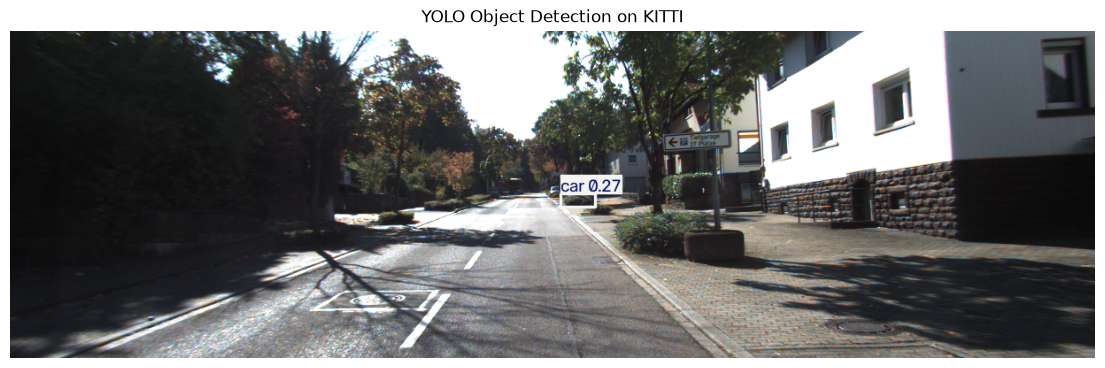

Detected objects: 1


In [5]:
results = model.predict(
    source=str(left_path),
    imgsz=640,
    conf=0.25,
    device=0 if torch.cuda.is_available() else "cpu",
    verbose=False
)

result = results[0]

annotated_image = result.plot()

plt.figure(figsize=(14, 7))
plt.imshow(cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB))
plt.title("YOLO Object Detection on KITTI")
plt.axis("off")
plt.show()

print("Detected objects:", len(result.boxes))

In [6]:
print("Detected objects:", len(result.boxes))

print("\nDetection details:")

for box in result.boxes:
    class_id = int(box.cls[0])
    confidence = float(box.conf[0])
    x1, y1, x2, y2 = box.xyxy[0].tolist()

    print(
        f"Class: {model.names[class_id]:12s} | "
        f"Confidence: {confidence:.3f} | "
        f"Bounding box: ({x1:.1f}, {y1:.1f}, "
        f"{x2:.1f}, {y2:.1f})"
    )

Detected objects: 1

Detection details:
Class: car          | Confidence: 0.273 | Bounding box: (623.0, 184.3, 661.4, 199.9)
